# Первая нейронная сеть: Fashion-MNIST

Научимся распознавать вид одежды по изображению.
Сравним линейную модель и две небольшие нейросети, посмотрим ход обучения
и разберём несколько неверных ответов.

Данные лежат в папке `data`, интернет для их загрузки на занятии не нужен.

## 1. Подготовка

Запустите импорты. Обратите внимание на настройки: число эпох одинаково
у обеих сетей. В течение одной эпохи сеть проходит все учебные примеры
небольшими порциями и корректирует веса.

Для запуска нужны пакеты из `requirements.txt`.

In [1]:
from pathlib import Path
from time import perf_counter
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display
from threadpoolctl import threadpool_limits

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

RANDOM_STATE = 12
VALID_SIZE = 2000
EPOCHS = 25
BATCH_SIZE = 128
MODEL_THREADS = 2
DATA_PATH = Path('data/fashion_mnist_subset.npz')
EXPORT_DIR = Path('exports')
CLASS_NAMES = np.array(['Футболка / топ', 'Брюки', 'Пуловер', 'Платье', 'Пальто',
                        'Сандалии', 'Рубашка', 'Кроссовки', 'Сумка', 'Ботильоны'])
CLASS_SHORT = np.array(['Топ', 'Брюки', 'Пуловер', 'Платье', 'Пальто',
                        'Сандалии', 'Рубашка', 'Кроссовки', 'Сумка', 'Ботильоны'])
CLASSES = np.arange(len(CLASS_NAMES))
BLUE, GRAY = '#005DAA', '#687789'

plt.rcParams.update({'figure.figsize': (10, 5), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titlepad': 12, 'figure.dpi': 110})
pd.options.display.float_format = '{:.4f}'.format
assert DATA_PATH.exists(), 'Сохраните папку data рядом с блокнотом и запустите Jupyter из папки комплекта.'
print('Данные найдены:', DATA_PATH)

Данные найдены: data\fashion_mnist_subset.npz


## 2. Изображения и классы

Fashion-MNIST содержит чёрно-белые изображения 28 × 28 пикселей и метки
десяти видов одежды и обуви. Здесь метка обозначает категорию товара.

В комплект вошли **12 000 изображений из исходных 60 000 учебных**:
по 1 200 каждого класса. Ещё 10 000 изображений официального теста
оставлены для итоговой проверки. Сейчас работаем только с учебной частью.

Посмотрите форму массива, тип пикселей и число изображений каждого класса.
На картинках ниже показаны известные метки из набора данных.

In [2]:
with np.load(DATA_PATH, allow_pickle=False) as data:
    images_pool = data['images_pool']
    y_pool = data['labels_pool']
    pool_source_indices = data['pool_source_indices']

print('Изображения:', images_pool.shape, 'Тип:', images_pool.dtype)
print('Яркость пикселей:', images_pool.min(), '…', images_pool.max())
assert images_pool.shape == (12000, 28, 28)
assert images_pool.dtype == np.uint8 and np.isfinite(images_pool).all()
assert np.array_equal(np.unique(y_pool), CLASSES)
counts = pd.DataFrame({'Класс': CLASSES, 'Название': CLASS_NAMES,
                       'Изображений': np.bincount(y_pool, minlength=10)})
display(counts)

Изображения: (12000, 28, 28) Тип: uint8
Яркость пикселей: 0 … 255


,Класс,Название,Изображений
0,0,Футболка / топ,1200
1,1,Брюки,1200
2,2,Пуловер,1200
3,3,Платье,1200
4,4,Пальто,1200
5,5,Сандалии,1200
6,6,Рубашка,1200
7,7,Кроссовки,1200
8,8,Сумка,1200
9,9,Ботильоны,1200


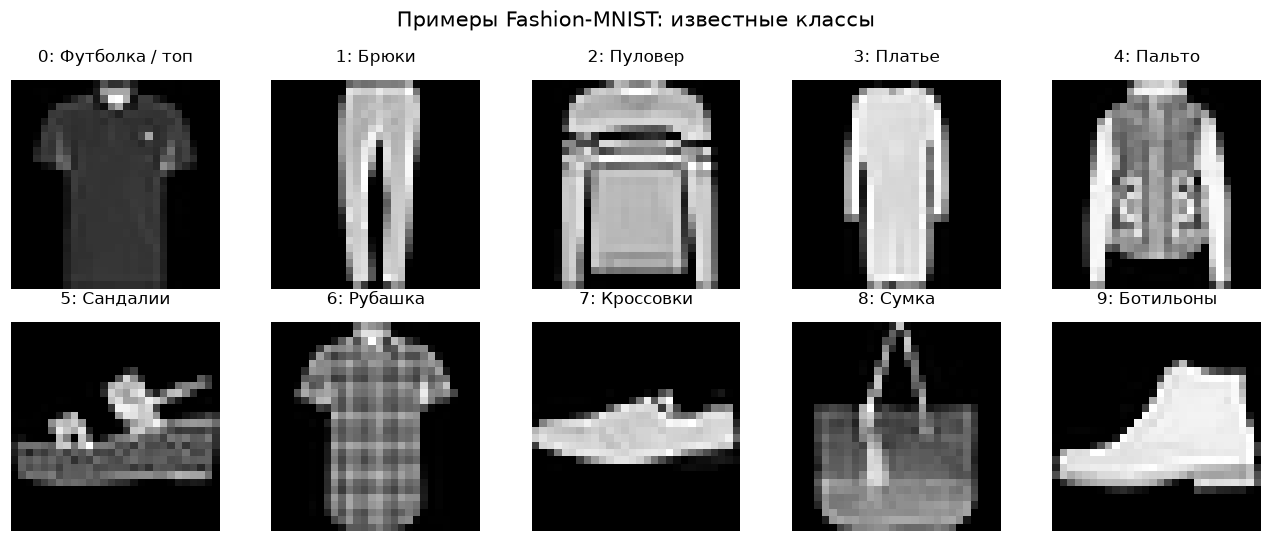

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for label, ax in enumerate(axes.flat):
    position = np.flatnonzero(y_pool == label)[0]
    ax.imshow(images_pool[position], cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'{label}: {CLASS_NAMES[label]}', fontsize=11)
    ax.axis('off')
fig.suptitle('Примеры Fashion-MNIST: известные классы', fontsize=14)
plt.tight_layout()
plt.show()

## 3. Подготовка входа и разделение данных

Для полносвязной сети превратите каждое изображение в строку из 784 чисел.
Порядок пикселей должен оставаться одинаковым у всех изображений.
Переведите массив в `float32` и разделите яркость на 255. Получится шкала от 0 до 1.

Из 12 000 записей выделите 2 000 для валидации. Признаки, метки и исходные
номера строк делите одним вызовом `train_test_split`. Используйте `stratify=y_pool`,
чтобы сохранить доли классов. Тест пока не загружаем.

Валидация нужна для выбора настроек. Итоговый тест используется после этого выбора.

In [4]:
X_pool = images_pool.reshape(len(images_pool), -1).astype(np.float32) / np.float32(255.0)  # изображения в строки, float32, яркость от 0 до 1
X_train, X_valid, y_train, y_valid, train_ids, valid_ids = train_test_split(
    X_pool, y_pool, pool_source_indices,
    test_size=VALID_SIZE, random_state=RANDOM_STATE, stratify=y_pool,
)
assert X_train.shape == (10000, 784) and X_valid.shape == (2000, 784)
assert X_train.dtype == np.float32 and 0 <= X_train.min() <= X_train.max() <= 1
assert set(train_ids).isdisjoint(valid_ids)
print('Обучение:', X_train.shape, 'Валидация:', X_valid.shape)
print('Первые 12 значений первой записи:', X_train[0, :12])

Обучение: (10000, 784) Валидация: (2000, 784)
Первые 12 значений первой записи: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


**Коротко запишите:** откуда взялось число 784? Почему метка класса хранится
отдельно от пикселей? Изменилось ли содержание изображения после деления на 255?

**Ответ:**
- **Откуда взялось число 784:** каждое изображение имеет размер 28 × 28 пикселей. При разворачивании двумерной матрицы в одну строку для подачи в полносвязную сеть получается `28 × 28 = 784` числовых признака.
- **Почему метка класса хранится отдельно от пикселей:** пиксели — это входные признаки (`X`), по которым модель строит прогноз, а метка (`y`) — правильный ответ (целевая переменная), нужный для обучения и проверки качества. Если включить метку во входные данные, возникнет утечка целевой переменной, а для новых изображений метка изначально неизвестна.
- **Изменилось ли содержание изображения после деления на 255:** нет. Деление всех пикселей на 255 — это линейное масштабирование яркости из диапазона `[0, 255]` в `[0, 1]`. Форма предмета, контуры и относительные контрасты полностью сохраняются, но численная оптимизация весов проходит стабильнее.

## 4. Линейная модель для сравнения

Обучите `LogisticRegression` на `X_train` и `y_train`, получите ответы для
`X_valid`. Здесь это классификатор, несмотря на слово Regression в названии.

Посчитайте accuracy на валидации: долю правильных ответов. Мы будем сравнивать
нейросеть с этой моделью на одних данных. Заранее ожидать победу нейросети не нужно.

In [5]:
linear = LogisticRegression(max_iter=500, tol=0.001, random_state=RANDOM_STATE)
started = perf_counter()
with threadpool_limits(limits=MODEL_THREADS):
    linear.fit(X_train, y_train)  # обучить linear
    y_valid_linear = linear.predict(X_valid)  # ответы linear для валидации
linear_seconds = perf_counter() - started
print(f'Accuracy, валидация: {accuracy_score(y_valid, y_valid_linear):.2%}')
print(f'Обучение и прогноз заняли {linear_seconds:.1f} с на этой машине')

Accuracy, валидация: 83.80%
Обучение и прогноз заняли 1.0 с на этой машине


## 5. Сеть с одним скрытым слоем

На входе 784 значения пикселей. В скрытом слое 16 нейронов: каждый вычисляет
взвешенную сумму входов и применяет нелинейную функцию ReLU. На выходе сеть
выдаёт оценки десяти классов.

Функция `train_network` готова. Внутри `partial_fit` продолжает обучение
на одну эпоху. Обычный повторный вызов `fit` для этой задачи не используем:
нам нужно сохранить веса и состояние обучения между эпохами.

Допишите вызов функции для `small_network`. В каждой эпохе мы только измеряем
качество на валидации. Веса меняются по учебным примерам.

In [6]:
def train_network(model, X_train, y_train, X_valid, y_valid):
    history_rows = []
    started = perf_counter()
    with threadpool_limits(limits=MODEL_THREADS):
        for epoch in range(1, EPOCHS + 1):
            model.partial_fit(X_train, y_train, classes=CLASSES)
            history_rows.append({
                'Эпоха': epoch,
                'Функция потерь, обучение': model.loss_,
                'Accuracy, обучение': accuracy_score(y_train, model.predict(X_train)),
                'Accuracy, валидация': accuracy_score(y_valid, model.predict(X_valid)),
            })
            if epoch % 5 == 0:
                print(f"Эпоха {epoch:2d}: loss={model.loss_:.3f}, "
                      f"accuracy на валидации={history_rows[-1]['Accuracy, валидация']:.2%}")
    print(f'Время обучения и измерений: {perf_counter() - started:.1f} с')
    return pd.DataFrame(history_rows)

In [7]:
small_network = MLPClassifier(
    hidden_layer_sizes=(16,), activation='relu', solver='adam',
    batch_size=BATCH_SIZE, learning_rate_init=0.001, alpha=0.0001,
    shuffle=True, random_state=RANDOM_STATE,
)
history_small = train_network(small_network, X_train, y_train, X_valid, y_valid)  # train_network: модель и четыре учебных/валидационных массива
print('Матрицы весов:', [weights.shape for weights in small_network.coefs_])
print('Обучаемых параметров:', sum(w.size for w in small_network.coefs_)
      + sum(b.size for b in small_network.intercepts_))

Эпоха  5: loss=0.558, accuracy на валидации=82.90%


Эпоха 10: loss=0.461, accuracy на валидации=83.65%


Эпоха 15: loss=0.409, accuracy на валидации=84.20%


Эпоха 20: loss=0.374, accuracy на валидации=84.40%


Эпоха 25: loss=0.350, accuracy на валидации=84.35%
Время обучения и измерений: 1.2 с
Матрицы весов: [(784, 16), (16, 10)]
Обучаемых параметров: 12730


## 6. Ход обучения

Постройте готовые графики. Слева показана функция потерь на обучении:
она учитывает, какие оценки сеть даёт классам, и штраф за большие веса.
Справа accuracy на учебных и валидационных примерах.

Падение loss само по себе не гарантирует улучшение на новых изображениях.
Посмотрите, движутся ли обе кривые accuracy одинаково. В основной работе
каждая сеть проходит ровно 25 эпох; здесь нет выбора лучшей эпохи по графику.

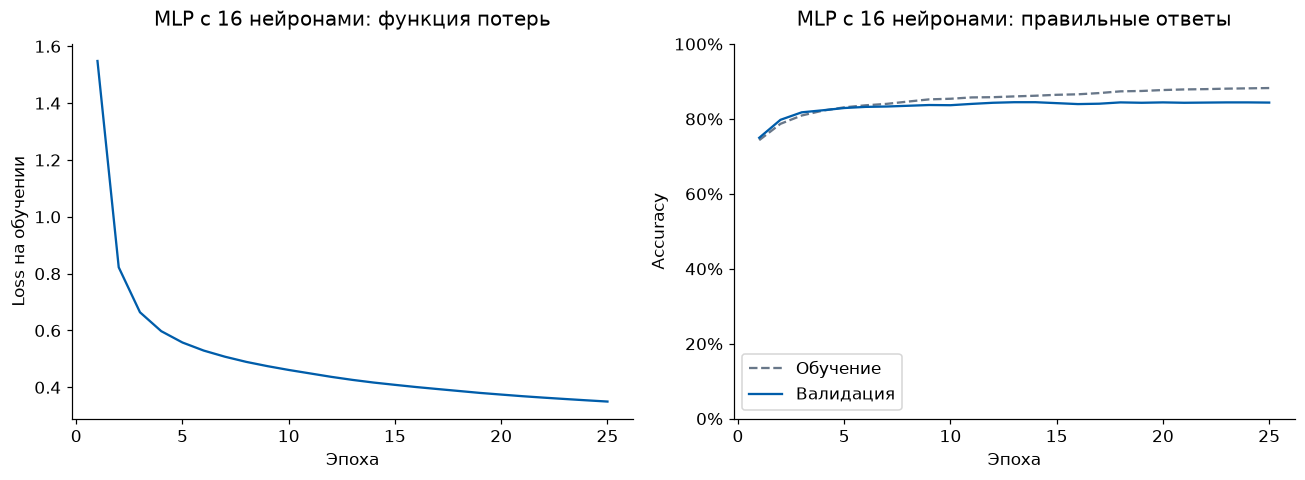

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(history_small['Эпоха'], history_small['Функция потерь, обучение'], color=BLUE)
axes[0].set(title='MLP с 16 нейронами: функция потерь',
            xlabel='Эпоха', ylabel='Loss на обучении')
axes[1].plot(history_small['Эпоха'], history_small['Accuracy, обучение'],
             color=GRAY, linestyle='--', label='Обучение')
axes[1].plot(history_small['Эпоха'], history_small['Accuracy, валидация'],
             color=BLUE, label='Валидация')
axes[1].set(title='MLP с 16 нейронами: правильные ответы',
            xlabel='Эпоха', ylabel='Accuracy', ylim=(0, 1))
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].legend()
plt.tight_layout()
plt.show()

**По своим графикам:** как изменилась loss? Есть ли разрыв между обучением
и валидацией? Можно ли считать, что ещё сто эпох обязательно улучшат результат?

**Ответ:**
- **Как изменилась loss:** функция потерь на обучении монотонно убывала на всех 25 эпохах — сначала быстро (с `1.548` на 1-й эпохе до `0.558` к 5-й эпохе), а затем всё более полого, снизившись до `0.350` к 25-й эпохе.
- **Есть ли разрыв между обучением и валидацией:** да. До 5-й эпохи обе кривые accuracy шли практически вместе (`83.08%` на обучении и `82.90%` на валидации), после чего качество на обучении продолжило расти до `88.23%`, а валидационная accuracy вышла на плато в районе `84.0–84.45%` примерно с 12–13-й эпохи и к 25-й эпохе составила `84.35%`. Итоговый разрыв составил `3.88` процентных пункта.
- **Улучшат ли результат ещё сто эпох:** нет, этого гарантировать нельзя. Поскольку валидационная accuracy уже перестала расти, дальнейшее снижение loss на обучении с высокой вероятностью приведёт к переобучению: сеть продолжит подстраиваться под учебные примеры, разрыв между кривыми увеличится, а качество на новых данных не улучшится или даже ухудшится.

## 7. Больше нейронов

Обучите вторую сеть с 64 нейронами. Число эпох, шаг обучения, исходные
примеры и остальные настройки оставьте прежними. Здесь мы меняем только
ширину скрытого слоя.

Соберите таблицу для линейной модели и двух сетей. Accuracy показывает
долю правильных ответов. F1 macro усредняет F1 десяти классов с одинаковым
весом: посмотрите, согласуется ли она с accuracy.

In [9]:
wide_network = MLPClassifier(
    hidden_layer_sizes=(64,), activation='relu', solver='adam',
    batch_size=BATCH_SIZE, learning_rate_init=0.001, alpha=0.0001,
    shuffle=True, random_state=RANDOM_STATE,
)
history_wide = train_network(wide_network, X_train, y_train, X_valid, y_valid)  # продолжительность и данные такие же, как у первой сети

Эпоха  5: loss=0.448, accuracy на валидации=83.10%


Эпоха 10: loss=0.363, accuracy на валидации=84.25%


Эпоха 15: loss=0.309, accuracy на валидации=85.25%


Эпоха 20: loss=0.270, accuracy на валидации=85.40%


Эпоха 25: loss=0.237, accuracy на валидации=85.50%
Время обучения и измерений: 1.9 с


In [10]:
models = {'Линейная модель': linear, 'MLP 16': small_network, 'MLP 64': wide_network}
validation_rows = []
with threadpool_limits(limits=MODEL_THREADS):
    for name, model in models.items():
        valid_prediction = model.predict(X_valid)
        validation_rows.append({
            'Модель': name,
            'Accuracy, обучение': accuracy_score(y_train, model.predict(X_train)),
            'Accuracy, валидация': accuracy_score(y_valid, valid_prediction),
            'F1 macro, валидация': f1_score(y_valid, valid_prediction, average='macro', zero_division=0),
        })
validation_results = pd.DataFrame(validation_rows)
display(validation_results.round(4))

,Модель,"Accuracy, обучение","Accuracy, валидация","F1 macro, валидация"
0,Линейная модель,0.9140,0.8380,0.8375
1,MLP 16,0.8823,0.8435,0.8426
2,MLP 64,0.9202,0.8550,0.8555


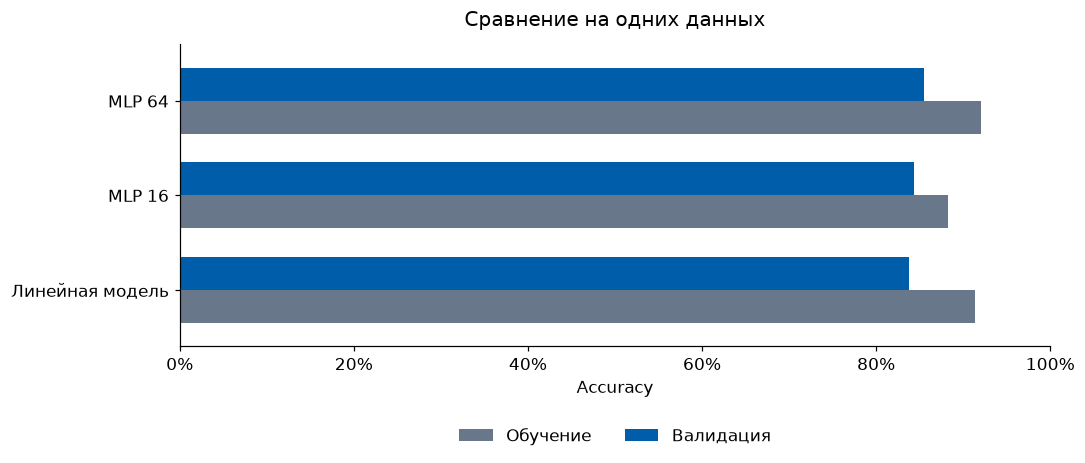

In [11]:
comparison = validation_results.set_index('Модель')[['Accuracy, обучение', 'Accuracy, валидация']]
comparison.columns = ['Обучение', 'Валидация']
ax = comparison.plot.barh(color=[GRAY, BLUE], figsize=(10, 4.5), width=0.7)
ax.set(title='Сравнение на одних данных', xlabel='Accuracy', ylabel='', xlim=(0, 1))
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

## 8. Выбор размера сети

Из двух сетей выберите вариант с большей accuracy на валидации. При равенстве
оставьте меньшую сеть. Линейную модель сохраним как отдельный ориентир.

Запишите имя выбранной сети в `best_network_name`, затем получите её из
словаря `models`. Продолжаем работать с уже обученной моделью. Валидационные
записи в её обучение не добавляем.

In [12]:
network_results = validation_results[validation_results['Модель'].isin(['MLP 16', 'MLP 64'])]
best_network_name = network_results.loc[network_results['Accuracy, валидация'].idxmax(), 'Модель']  # имя сети по правилу из задания
selected_network = models[best_network_name]
print('Выбор по валидации:', best_network_name)

Выбор по валидации: MLP 64


## 9. Итоговая проверка

Теперь загрузите официальный тест. Для него нужно точно такое же
преобразование пикселей, как на шаге 3. Получите ответы выбранной сети,
посчитайте accuracy и F1 macro. Сравнение с линейной моделью готово.

После просмотра теста основной эксперимент закончен. Если снова менять
сеть ради лучшего тестового результата, потребуется новая независимая проверка.

В матрице ошибок строка обозначает известный класс, столбец - ответ сети.
Числа на диагонали соответствуют правильным ответам.

In [13]:
with np.load(DATA_PATH, allow_pickle=False) as data:
    images_test = data['images_test']
    y_test = data['labels_test']
    test_ids = data['test_source_indices']
X_test = images_test.reshape(len(images_test), -1).astype(np.float32) / np.float32(255.0)  # та же форма, тип и шкала, что у учебных данных
with threadpool_limits(limits=MODEL_THREADS):
    y_pred_test = selected_network.predict(X_test)  # ответы выбранной сети
    y_pred_linear_test = linear.predict(X_test)
    test_probabilities = selected_network.predict_proba(X_test)
test_results = pd.DataFrame([
    {'Модель': 'Линейная модель', 'Accuracy, тест': accuracy_score(y_test, y_pred_linear_test),
     'F1 macro, тест': f1_score(y_test, y_pred_linear_test, average='macro', zero_division=0)},
    {'Модель': best_network_name, 'Accuracy, тест': accuracy_score(y_test, y_pred_test),
     'F1 macro, тест': f1_score(y_test, y_pred_test, average='macro', zero_division=0)},
])
assert len(y_pred_test) == len(y_test) == 10000
assert np.allclose(test_probabilities.sum(axis=1), 1, atol=1e-5)
display(test_results.round(4))

,Модель,"Accuracy, тест","F1 macro, тест"
0,Линейная модель,0.8242,0.8240
1,MLP 64,0.8460,0.8467


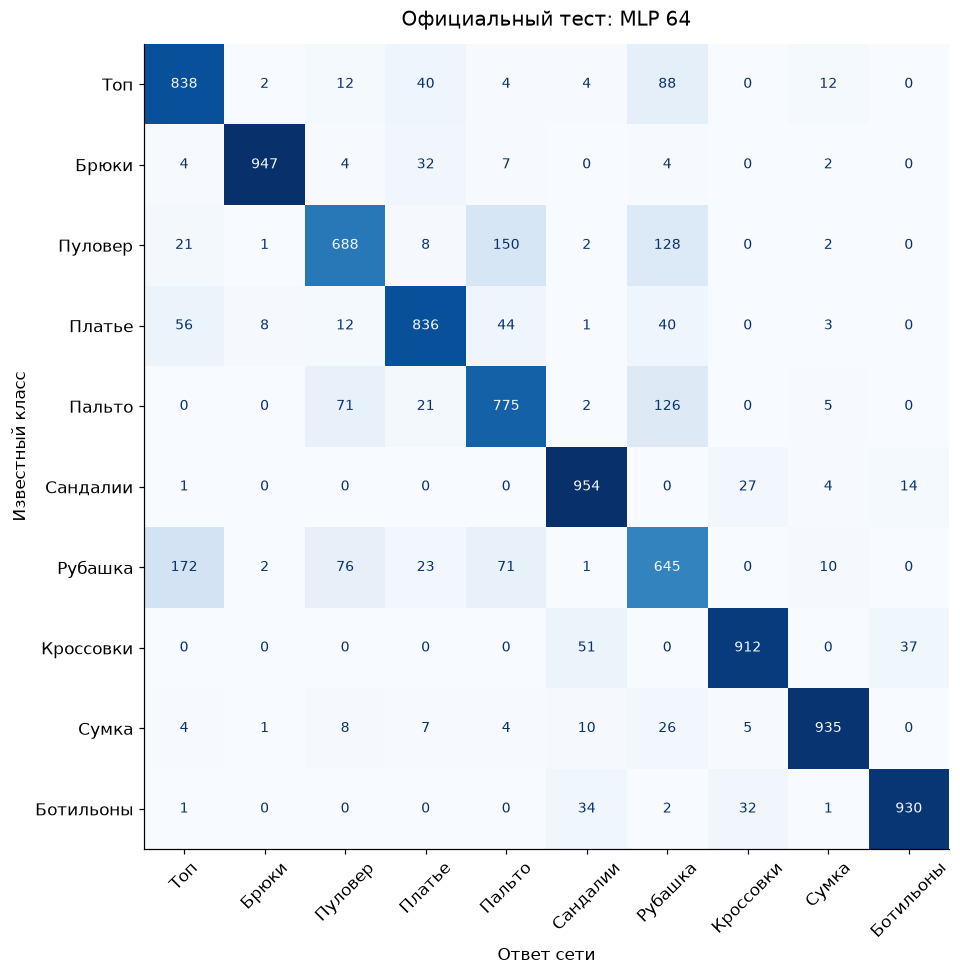

In [14]:
fig, ax = plt.subplots(figsize=(10, 9))
matrix_display = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_test, labels=CLASSES, display_labels=CLASS_SHORT,
    cmap='Blues', colorbar=False, values_format='d',
    xticks_rotation=45, ax=ax, text_kw={'fontsize': 9},
)
ax.set(title=f'Официальный тест: {best_network_name}',
       xlabel='Ответ сети', ylabel='Известный класс')
plt.tight_layout()
plt.show()
assert matrix_display.confusion_matrix.sum() == len(y_test)

**Объясните по матрице:** какие классы сеть путает? Назовите одну клетку
вне диагонали словами. Почему общей accuracy недостаточно для описания всех ошибок?

**Ответ:**
- **Какие классы сеть путает:** основная часть ошибок сосредоточена среди категорий верхней одежды со схожим силуэтом — прежде всего «Рубашка», «Топ», «Пуловер» и «Пальто» (а также частично «Платье» с «Топом» — 56, «Пальто» — 44 и «Рубашкой» — 40). Заметно реже путаница происходит внутри обувных классов («Кроссовки» → «Сандалии»: 51, «Кроссовки» → «Ботильоны»: 37, «Ботильоны» → «Сандалии»: 34, «Ботильоны» → «Кроссовки»: 32). Классы с ярко выраженной формой («Сандалии» — 954/1000, «Брюки» — 947/1000, «Сумка» — 935/1000, «Ботильоны» — 930/1000) сеть распознаёт уверенно, а между разными группами товаров (например, обувь и верхняя одежда) ошибок почти нет.
- **Клетка вне диагонали словами:** в строке **«Рубашка»** и столбце **«Топ»** стоит число **172** — это означает, что 172 тестовых изображения с известным классом «Рубашка» сеть ошибочно отнесла к классу «Футболка / топ» (это самая крупная ошибка в матрице; также велики клетки «Пуловер» → «Пальто» — 150, «Пуловер» → «Рубашка» — 128 и «Пальто» → «Рубашка» — 126).
- **Почему общей accuracy недостаточно:** общая accuracy (`84.60%`) даёт лишь среднюю долю верных ответов по всем 10 000 изображениям и скрывает, какие именно классы распознаются плохо и куда направлены ошибки. Например, при общей точности `84.60%` доля верных ответов для «Сандалий» составляет `95.4%`, а для «Рубашки» — лишь `64.5%`, для «Пуловера» — `68.8%`. Матрица ошибок позволяет увидеть эти проблемные классы и конкретные пары путаницы.

## 10. Изображения с ошибками

Найдите позиции, где `y_pred_test` отличается от `y_test`. Покажите первые
шесть ошибок в порядке тестового набора. Изображения, правильные классы и
ответы сети берите по одним позициям.

Под каждым изображением приведена наибольшая оценка класса от `predict_proba`.
Гарантирует ли это правильный ответ?

Неверных ответов: 1540 из 10000


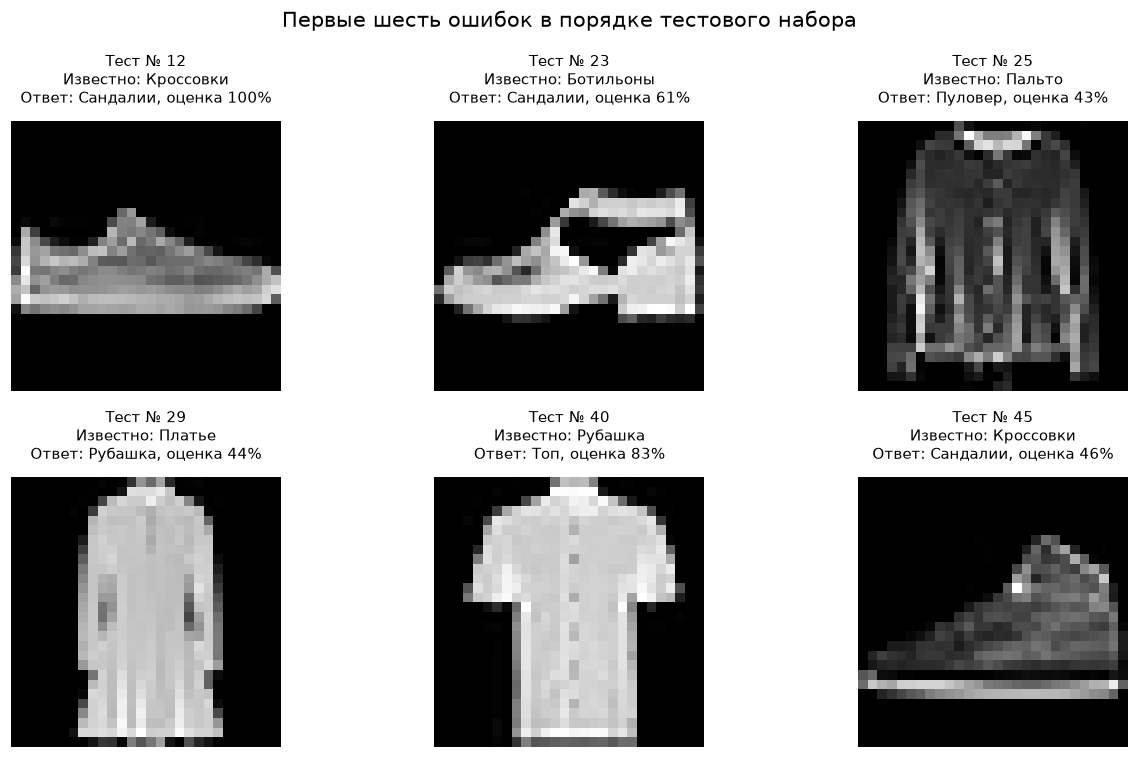

In [15]:
mistake_positions = np.flatnonzero(y_pred_test != y_test)  # номера позиций с неверным ответом
print('Неверных ответов:', len(mistake_positions), 'из', len(y_test))
error_positions = mistake_positions[:6]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, position in zip(axes.flat, error_positions):
    predicted = y_pred_test[position]
    score = test_probabilities[position].max()
    ax.imshow(images_test[position], cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'Тест № {test_ids[position]}\n'
                 f'Известно: {CLASS_SHORT[y_test[position]]}\n'
                 f'Ответ: {CLASS_SHORT[predicted]}, оценка {score:.0%}', fontsize=10)
    ax.axis('off')
for ax in axes.flat[len(error_positions):]:
    ax.axis('off')
fig.suptitle('Первые шесть ошибок в порядке тестового набора', fontsize=14)
plt.tight_layout()
plt.show()

Выберите одну ошибку. Какие детали изображения могли затруднить различение?
Запишите предположение и отделите его от того, что вы действительно видите.

**Ответ (на примере Тест № 40: известно «Рубашка», ответ сети «Топ», оценка 83%):**
- **Что действительно видно:** на чёрно-белом изображении `28 × 28` показан светлый предмет верхней одежды с короткими рукавами и прямым силуэтом. По вертикальной оси в центре различимы несколько мелких слабоконтрастных серых точек (пуговицы) и узкий край у ворота. Сеть выбрала класс «Топ» с оценкой `83%`.
- **Предположение о причине ошибки:** по общему силуэту (короткие рукава, длина и контур) эта рубашка практически совпадает с футболкой/топом, тогда как отличительные признаки рубашки — воротник и вертикальный ряд пуговиц — в разрешении `28 × 28` выглядят размытыми и занимают лишь несколько пикселей. Поскольку полносвязная сеть опирается в первую очередь на общую форму и распределение яркости по вектору из 784 чисел, она могла классифицировать объект по силуэту футболки.
- **Оценка вероятности и правильность ответа:** высокая оценка от `predict_proba` не гарантирует верного прогноза — это хорошо видно как на Тест № 40 (`83%`), так и особенно на Тест № 12, где для кроссовок сеть выдала ответ «Сандалии» с оценкой `100%` и ошиблась.

## 11. Один прогноз и экспорт

Подготовьте первое тестовое изображение как массив формы `(1, 784)`
в той же шкале от 0 до 1. Получите оценки классов и покажите три наибольшие.
Номер столбца вероятностей связывайте с `selected_network.classes_`.

Это демонстрация применения уже проверенной модели к одной записи из того же
теста. Она не является дополнительной независимой проверкой.

Запустите готовый экспорт. В папке `exports` появятся четыре CSV.

,Класс,Оценка
0,Ботильоны,0.8087
1,Сандалии,0.1499
2,Кроссовки,0.0397


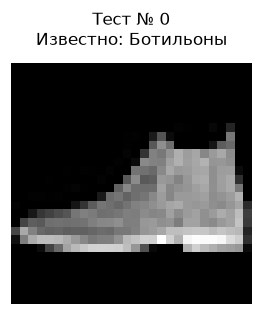

In [16]:
example_position = 0
new_image = images_test[example_position]
new_X = new_image.reshape(1, -1).astype(np.float32) / np.float32(255.0)  # одна строка, 784 признака, float32, шкала от 0 до 1
with threadpool_limits(limits=MODEL_THREADS):
    example_probabilities = selected_network.predict_proba(new_X)[0]  # оценки десяти классов для одной записи
top_positions = np.argsort(example_probabilities)[::-1][:3]
top_classes = selected_network.classes_[top_positions]
display(pd.DataFrame({'Класс': CLASS_NAMES[top_classes],
                      'Оценка': example_probabilities[top_positions]}))
fig, ax = plt.subplots(figsize=(3, 3))
ax.imshow(new_image, cmap='gray', vmin=0, vmax=255)
ax.set_title(f'Тест № {test_ids[example_position]}\n'
             f'Известно: {CLASS_NAMES[y_test[example_position]]}', fontsize=11)
ax.axis('off')
plt.tight_layout()
plt.show()

In [17]:
EXPORT_DIR.mkdir(exist_ok=True)
validation_results.to_csv(EXPORT_DIR / 'validation_comparison.csv', index=False, encoding='utf-8-sig')
test_results.to_csv(EXPORT_DIR / 'test_metrics.csv', index=False, encoding='utf-8-sig')
test_predictions = pd.DataFrame({
    'test_index': test_ids,
    'known_class': y_test, 'known_name': CLASS_NAMES[y_test],
    'predicted_class': y_pred_test, 'predicted_name': CLASS_NAMES[y_pred_test],
    'max_probability': test_probabilities.max(axis=1),
    'correct': y_pred_test == y_test,
})
test_predictions.to_csv(EXPORT_DIR / 'test_predictions.csv', index=False, encoding='utf-8-sig')
training_history = pd.concat([
    history_small.assign(Модель='MLP 16'), history_wide.assign(Модель='MLP 64')], ignore_index=True)
training_history.to_csv(EXPORT_DIR / 'training_history.csv', index=False, encoding='utf-8-sig')
print('Сохранено в папку:', EXPORT_DIR.resolve())
print('validation_comparison.csv, test_metrics.csv, test_predictions.csv, training_history.csv')

Сохранено в папку: M:\Projects\pythonM\study\the_basics_of_ai_lb5\exports
validation_comparison.csv, test_metrics.csv, test_predictions.csv, training_history.csv


## 12. Вывод

Напишите выводы по своим результатам. Укажите, какую сеть выбрали
и по какой выборке. Сравните её с линейной моделью, опишите ход обучения
и одну конкретную ошибку. Назовите ограничение проведённой проверки.

**Мой вывод:**

1. **Выбор модели и выборка для выбора:** по результатам на валидационной выборке (`2 000` изображений из `12 000` учебных при `RANDOM_STATE = 12`, `EPOCHS = 25`, `BATCH_SIZE = 128`) выбрана нейросеть **`MLP 64`**: её accuracy на валидации составила **`85.50%`** (`F1 macro = 0.8555`), что выше, чем у `MLP 16` (**`84.35%`**, `F1 macro = 0.8426`). Выбор выполнен строго по валидации, без обращения к тесту и без дообучения на валидационных данных.
2. **Сравнение с линейной моделью:** на валидации обе нейросети обошли `LogisticRegression` (`Accuracy = 83.80%`, `F1 macro = 0.8375`), при этом `MLP 64` превзошла линейный ориентир на `+1.70` п.п. На официальном тесте (`10 000` изображений) преимущество подтвердилось: **`MLP 64`** показала **`Accuracy = 84.60%`** и **`F1 macro = 0.8467`**, тогда как линейная модель — **`Accuracy = 82.42%`** и **`F1 macro = 0.8240`** (`+2.18` п.п. по accuracy и `+0.0227` по F1 macro). Близость значений `Accuracy` и `F1 macro` объясняется сбалансированностью всех десяти классов.
3. **Ход обучения:** у `MLP 16` функция потерь на обучении монотонно падала с `1.548` до `0.350`, учебная accuracy выросла с `74.32%` до `88.23%`, а валидационная accuracy стабилизировалась около `84.0–84.45%` примерно с 12–13-й эпохи (`84.35%` к 25-й эпохе, разрыв `3.88` п.п.). У `MLP 64` loss снизилась с `0.967` до `0.237`, учебная accuracy достигла `92.02%`, а валидационная — `85.50%` (разрыв `6.52` п.п.). Увеличение разрыва при замедлении роста на валидации указывает на начало переобучения, поэтому простое увеличение числа эпох не гарантирует дальнейшего улучшения качества.
4. **Анализ ошибок:** на тесте `MLP 64` допустила `1 540` ошибок из `10 000`. По матрице ошибок сеть хуже всего различает похожую верхнюю одежду — «Рубашку» (`645/1000`), «Пуловер» (`688/1000`) и «Пальто» (`775/1000`); самая частая ошибка — «Рубашка» → «Топ» (`172` случая), далее «Пуловер» → «Пальто» (`150`) и «Пуловер» → «Рубашка» (`128`). В качестве конкретного примера разобрана ошибка **Тест № 40** (известно: «Рубашка», ответ сети: «Топ», оценка `83%`), где короткие рукава и общий контур визуально близки к футболке, а мелкие пуговицы в разрешении `28 × 28` слабо различимы. На примере **Тест № 12** (известно: «Кроссовки», ответ: «Сандалии», оценка `100%`) также видно, что высокая оценка вероятности не гарантирует верного ответа. Демонстрационный прогноз для одной записи (`Тест № 0`, известны «Ботильоны») оказался верным: класс «Ботильоны» получил наибольшую оценку `80.87%`.
5. **Ограничения проведённой проверки и когда нужна новая проверка:**
   - Официальный тест уже использован для итоговой оценки: если после его просмотра менять архитектуру, число эпох или другие настройки ради улучшения результата, потребуется новая независимая тестовая выборка (иначе возникнет утечка информации о тесте).
   - Прогноз для `Тест № 0` в разделе 11 выполнен на записи из уже просмотренного теста и служит лишь демонстрацией применения модели, а не дополнительной независимой проверкой.
   - Полносвязная сеть (`MLP`) работает с плоским вектором из `784` пикселей и не использует пространственную структуру изображения (как это делают свёрточные сети), а обучение велось на `10 000` (из `60 000`) центрированных чёрно-белых изображений `28 × 28` на однородном фоне. Поэтому полученные метрики нельзя напрямую переносить на реальные фотографии одежды с телефона с иным фоном, ракурсом, цветом и освещением.

## Если осталось время

В отдельном эксперименте исследуйте другую ширину слоя или число эпох,
используя только обучение и валидацию. Сохраните основной результат отдельно.
Повторный выбор настроек по уже просмотренному тесту не даёт новой независимой оценки.

Сеть в этой работе полносвязная. Она получает строку пикселей и не использует
свёртки. Качество на Fashion-MNIST не переносится автоматически на фотографии
с телефона: фон, положение предмета, цвет и освещение будут другими.

Источники: [Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist),
[MLPClassifier и partial_fit](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html),
[правила проверки моделей](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).
Происхождение данных и контрольная сумма находятся в `data/source.json`.